In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import spacy

from collections import Counter
from wordcloud import WordCloud

from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from sklearn.metrics import roc_auc_score, roc_curve, auc, confusion_matrix

import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow import keras
from transformers import AutoTokenizer, TFBertForSequenceClassification

# !pip install datasets

from datasets import load_dataset
import sys
import pathlib
import importlib
import joblib
import os

from tensorflow.keras.preprocessing.text import tokenizer_from_json
import json

# sys.path.append("../scripts/")

%matplotlib inline

In [ ]:
!python -m spacy download en_core_web_lg
nlp = spacy.load("en_core_web_lg")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.7/400.7 MB 3.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_lg')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# Enron
# SpamAssassin - Done
# LingSpam - Done
name = "Enron"

In [ ]:
mitDF = pd.read_csv(f"drive/MyDrive/Dissertation/Datasets/{name}/{name}.csv")#, encoding="latin1")

In [ ]:
# # Ling Spam
# mitDF = mitDF.loc[:, ~mitDF.columns.str.startswith("subject")]
# mitDF.rename({'message':'text'}, axis=1, inplace=True)

In [ ]:
shuffled_df = mitDF.sample(n=len(mitDF))
shuffled_df = shuffled_df.reset_index(drop=True)

In [ ]:
shuffled_df.head(30)

,text,label
0,Subject: sexual rebirth\nhow to save on your m...,1
1,"Subject: cash : $ 48463\ndear homeowner , you ...",1
2,Subject: various market data charges to the re...,0
3,Subject: greatest online medication here\nfuzz...,1
4,Subject: update on confirmlogic\ni wanted to g...,0
5,Subject: your golf buddy\nit ' s official !\ny...,1
6,"Subject: resumes\nkaren ,\ni have forwarded al...",0
7,Subject: lowe  s * or home depot * ? which ho...,1
8,Subject: fw : csfb independent power weekly - ...,0
9,Subject: re : end of quarter origination numbe...,0


In [ ]:
shuffled_df.shape

(33716, 2)

In [ ]:
shuffled_df.columns

Index(['text', 'label'], dtype='object')

# Visualization of Data + results

In [ ]:
mitDF_vis = shuffled_df.copy(deep=True)

In [ ]:
# Update the 0 and 1 with Ham and Spam
# mitDF_vis['word_label'] = mitDF_vis["label"].map({"ham":0, "spam":1})
mitDF_vis['word_label'] = mitDF_vis["label"]

In [ ]:
mitDF_vis

,text,label,word_label
0,Received: from hq.pro-ns.net (localhost [127.0...,1,1
1,From webdeals@7a6a.net Mon Jun 24 17:48:34 20...,1,1
2,From rpm-list-admin@freshrpms.net Thu Aug 29 ...,0,0
3,From social-admin@linux.ie Fri Jul 26 12:04:3...,1,1
4,From spamassassin-devel-admin@lists.sourceforg...,0,0
...,...,...,...
4193,From fork-admin@xent.com Sun Sep 22 14:11:45 ...,0,0
4194,From sitescooper-talk-admin@lists.sourceforge....,0,0
4195,From ilug-admin@linux.ie Mon Oct 7 12:06:33 ...,0,0
4196,From seemsg_8452970@gmx.net Wed Jul 24 10:43:...,1,1


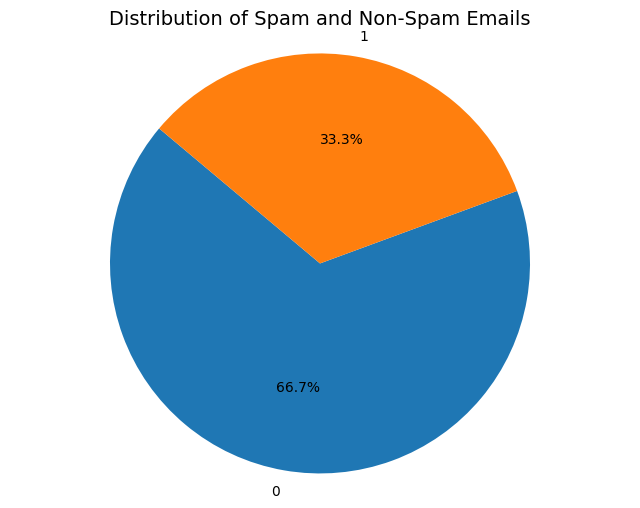

In [ ]:
# Visualize the Percent difference between Spam and Ham
Total_percent = mitDF_vis['word_label'].value_counts()

plt.figure(figsize=(8, 6))
plt.pie(Total_percent, autopct="%1.1f%%", labels=Total_percent.index, startangle=140)
plt.title("Distribution of Spam and Non-Spam Emails", fontsize=14)
plt.axis('equal')
plt.savefig('distribution_of_spam_ham.png', format='png')
# plt.show()

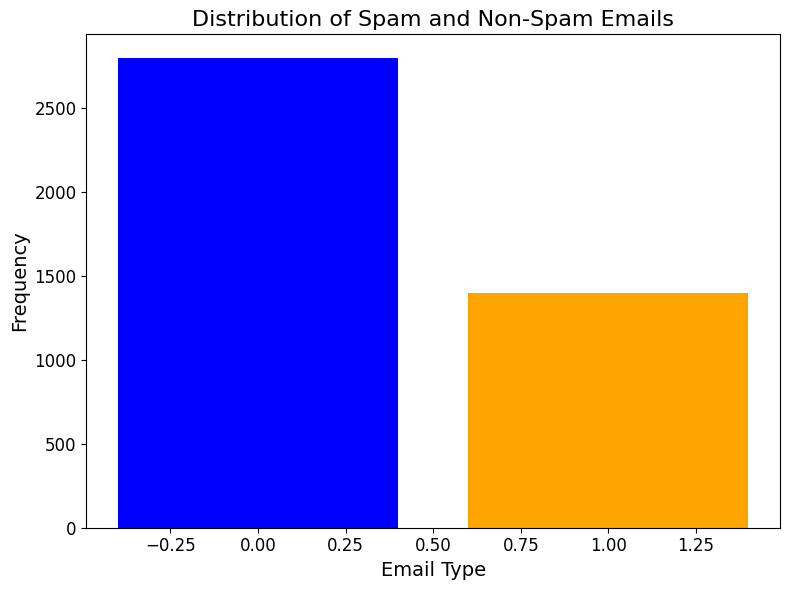

In [ ]:
plt.figure(figsize=(8, 6))
plt.bar(Total_percent.index, Total_percent.values, color=['blue', 'orange'])
plt.title("Distribution of Spam and Non-Spam Emails", fontsize=16)
plt.xlabel('Email Type', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.savefig('distribution_bar_of_spam_ham.png', format='png')

In [ ]:
# Counting the characters, words, and sentences for each text
def LengthSizeWise(text):
    doc = nlp(text)

    lengthText   = len(text)
    wordText     = len([word for word in doc if not word.is_punct and not word.is_space])
    sentenceText = len(list(doc.sents))

    return pd.Series([lengthText, wordText, sentenceText])

mitDF_vis[['char_count', 'word_count', 'sentence_count']] = mitDF_vis['text'].apply(LengthSizeWise)

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipython-input-1837210068.py", line 11, in <cell line: 0>
    mitDF_vis[['char_count', 'word_count', 'sentence_count']] = mitDF_vis['text'].apply(LengthSizeWise)
                                                                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pandas/core/series.py", line 4924, in apply
    ).apply()
      ^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pandas/core/apply.py", line 1427, in apply
    return self.apply_standard()
           ^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pandas/core/apply.py", line 1507, in apply_standard
    mapped = obj._map_values(
             ^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pandas/core/base.py", line 921, in _map_va

TypeError: object of type 'NoneType' has no len()

In [ ]:
# Total of Ham and Spam
total_ham_count  = mitDF_vis[mitDF_vis['word_label'] == 'Ham']['char_count'].sum()
total_spam_count = mitDF_vis[mitDF_vis['word_label'] == 'Spam']['char_count'].sum()

# Total word of Ham and Spam
total_word_ham_count  = mitDF_vis[mitDF_vis['word_label'] == 'Ham']['word_count'].sum()
total_word_spam_count = mitDF_vis[mitDF_vis['word_label'] == 'Spam']['word_count'].sum()

# Total sentene of Ham and Spam
total_sent_ham_count  = mitDF_vis[mitDF_vis['word_label'] == 'Ham']['sentence_count'].sum()
total_sent_spam_count = mitDF_vis[mitDF_vis['word_label'] == 'Spam']['sentence_count'].sum()

# Obtain the Spam proportion for length, word, and sentences
length_spam_proportion = total_spam_count/(total_ham_count + total_spam_count)
word_spam_proportion   = total_word_spam_count/(total_word_ham_count + total_word_spam_count)
sent_spam_proportion   = total_sent_spam_count/(total_sent_spam_count + total_sent_ham_count)

print("Length of spam email proportion:", length_spam_proportion)
print("Word spam email proportion:", word_spam_proportion)
print("Sentence spam email proportion:", sent_spam_proportion)

Length of spam email proportion: nan
Word spam email proportion: nan
Sentence spam email proportion: nan


/tmp/ipython-input-1388955390.py:14: RuntimeWarning: invalid value encountered in scalar divide
  length_spam_proportion = total_spam_count/(total_ham_count + total_spam_count)
/tmp/ipython-input-1388955390.py:15: RuntimeWarning: invalid value encountered in scalar divide
  word_spam_proportion   = total_word_spam_count/(total_word_ham_count + total_word_spam_count)
/tmp/ipython-input-1388955390.py:16: RuntimeWarning: invalid value encountered in scalar divide
  sent_spam_proportion   = total_sent_spam_count/(total_sent_spam_count + total_sent_ham_count)


In [ ]:
# Average length of emails
average_ham_email  = mitDF_vis[mitDF_vis['word_label'] == 'Ham']['char_count'].mean()
average_spam_email = mitDF_vis[mitDF_vis['word_label'] == 'Spam']['char_count'].mean()

print(average_ham_email, average_spam_email)

plt.figure(figsize=(8,6))
plt.bar(['Ham', 'Spam'], [average_ham_email, average_spam_email], color=['orange', 'blue'])
plt.title("Total Length of Emails by Class", fontsize=16)
plt.xlabel("Email Type", fontsize=14)
plt.ylabel("Average Length of Texts", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.savefig('average_length_of_spam_ham.png', format='png')
# plt.show()

nan nan


In [ ]:
# Average word length of emails
average_word_ham_email  = mitDF_vis[mitDF_vis['word_label'] == 'Ham']['word_count'].mean()
average_word_spam_email = mitDF_vis[mitDF_vis['word_label'] == 'Spam']['word_count'].mean()

print(average_word_ham_email, average_word_spam_email)

plt.figure(figsize=(8,6))
plt.bar(['Ham', 'Spam'], [average_word_ham_email, average_word_spam_email], color=['orange', 'blue'])
plt.title("Average Number of Words per Email", fontsize=16)
plt.xlabel("Email Type", fontsize=14)
plt.ylabel("Average Word Count", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.savefig('average_length_word_of_spam_ham.png', format='png')
# plt.show()

nan nan


In [ ]:
# Average sentence length of emails
average_sent_ham_email  = mitDF_vis[mitDF_vis['word_label'] == 'Ham']['sentence_count'].mean()
average_sent_spam_email = mitDF_vis[mitDF_vis['word_label'] == 'Spam']['sentence_count'].mean()

print(average_sent_ham_email, average_sent_spam_email)

plt.figure(figsize=(8,6))
plt.bar(['Ham', 'Spam'], [average_sent_ham_email, average_sent_spam_email], color=['orange', 'blue'])
plt.title("Average Number of Sentences per Email", fontsize=16)
plt.xlabel("Email Type", fontsize=14)
plt.ylabel("Average Sentence Count", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.savefig('average_length_sentence_of_spam_ham.png', format='png')
# plt.show()

nan nan


In [ ]:
# Relationship between Features
correlation_matrix = mitDF_vis[['char_count', 'word_count', 'sentence_count']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Features', fontsize=16)
plt.xlabel('Features', fontsize=14)
plt.ylabel('Features', fontsize=14)

plt.tight_layout()
# plt.show()
plt.savefig('correlation_matrix_of_spam_ham.png', format='png')

# Data Preprocessing

In [ ]:
import Clean_data
importlib.reload(Clean_data)

<module 'Clean_data' from '/content/Clean_data.py'>

In [ ]:
mit_copy = shuffled_df.copy(deep=True)

In [ ]:
mit_copy.head()

,text,label
0,Subject: sexual rebirth\nhow to save on your m...,1
1,"Subject: cash : $ 48463\ndear homeowner , you ...",1
2,Subject: various market data charges to the re...,0
3,Subject: greatest online medication here\nfuzz...,1
4,Subject: update on confirmlogic\ni wanted to g...,0


In [ ]:
# Matcher = True, it means that transformation of tokens into Abstract is being process.
# Matcher = False, it means that no transformation undegoes, except working on Regex.
phis = Clean_data.load_and_preprocess(mit_copy, name, matcher=True)

Not Good


100%|██████████| 33716/33716 [26:33<00:00, 21.16it/s] 


In [ ]:
phis.isna().sum()

,0
text,0
label,0
expanded_text,0
processed_text,0


In [ ]:
phis.dropna(inplace=True)

In [ ]:
(phis.shape, phis.size)

((33716, 4), 134864)

In [ ]:
phis[['expanded_text','processed_text']].head(5)

,expanded_text,processed_text
0,subject : sexual rebirth how to save on your m...,subject : sexual rebirth how to save on your m...
1,"subject : cash: $48463 dear homeowner , you ha...","subject : cash : MONEYNER dear homeowner , you..."
2,subject : various market data charges to the r...,subject : various market data charges to the r...
3,subject : greatest online medication here fuzz...,subject : greatest online medication here fuzz...
4,subject : update on confirmlogic i wanted to g...,subject : update on confirmlogic i wanted to g...


In [ ]:
# Most Common Words in Spam Emails using SpaCy
spam_emails_baseline = phis[phis['label'] == 1]['processed_text']
ham_emails_baseline  = phis[phis['label'] == 0]['processed_text']

In [ ]:
# Tokenize the text in spam emails
spam_words_baseline = ' '.join(spam_emails_baseline).split()
ham_words_baseline = ' '.join(ham_emails_baseline).split()

# Count occurrences of each word
word_count_spam_baseline = Counter(spam_words_baseline)
word_count_ham_baseline  = Counter(ham_words_baseline)

# Find the 10 most common words
most_common_words_spam_baseline = word_count_spam_baseline.most_common(30)
most_common_words_ham_baseline = word_count_ham_baseline.most_common(30)

print("Top 10 Most Common Words in Spam Emails without NER:")
for word, count in most_common_words_spam_baseline:
    print(f"{word}: {count} occurrences")

print('\n' ,'-'*70, '\n')

print("Top 10 Most Common Words in Ham Emails without NER:")
for word, count in most_common_words_ham_baseline:
    print(f"{word}: {count} occurrences")

# print('\n','-'*70, '\n')

# print("Top 10 Most Common Words in Spam Emails by SpaCy with NER:")
# for word, count in most_common_words_spam_ner:
#     print(f"{word}: {count} occurrences")

# print('\n', '-'*70, '\n')

# print("Top 10 Most Common Words in Ham Emails by SpaCy with NER:")
# for word, count in most_common_words_ham_ner:
#     print(f"{word}: {count} occurrences")

Top 10 Most Common Words in Spam Emails without NER:
.: 186795 occurrences
NUM_NER: 125761 occurrences
,: 117537 occurrences
the: 103351 occurrences
to: 79815 occurrences
-: 76676 occurrences
and: 68816 occurrences
of: 64109 occurrences
_: 56686 occurrences
:: 55668 occurrences
ORG_NER: 48983 occurrences
a: 48737 occurrences
you: 46774 occurrences
in: 43996 occurrences
PER_NER: 43685 occurrences
this: 33866 occurrences
your: 33751 occurrences
?: 33183 occurrences
for: 32821 occurrences
is: 31004 occurrences
/: 29275 occurrences
!: 28845 occurrences
DATE_NER: 28125 occurrences
MONEY_NER: 24034 occurrences
GPE_NER: 21031 occurrences
': 20001 occurrences
that: 19967 occurrences
i: 19937 occurrences
|: 19897 occurrences
with: 19618 occurrences

 ---------------------------------------------------------------------- 

Top 10 Most Common Words in Ham Emails without NER:
-: 231668 occurrences
.: 195937 occurrences
the: 168077 occurrences
NUM_NER: 154577 occurrences
PER_NER: 144904 occurrences

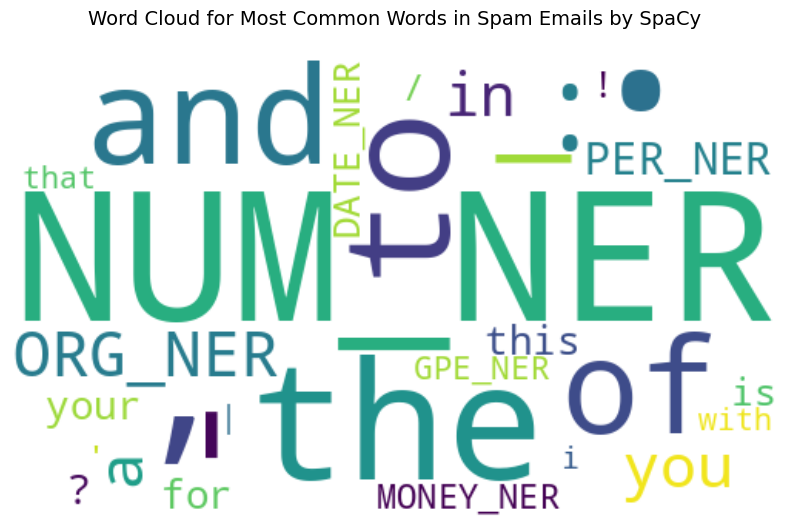

In [ ]:
# Plot Word Cloud
wordcloud = WordCloud(width=500, height=300, background_color='white').generate_from_frequencies(dict(most_common_words_spam_baseline))
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('Word Cloud for Most Common Words in Spam Emails by SpaCy',pad=25, fontdict={'fontsize':'14'})
plt.axis('off')
plt.savefig('word_cloud_spam_spacy.png', format='png')
# plt.show()

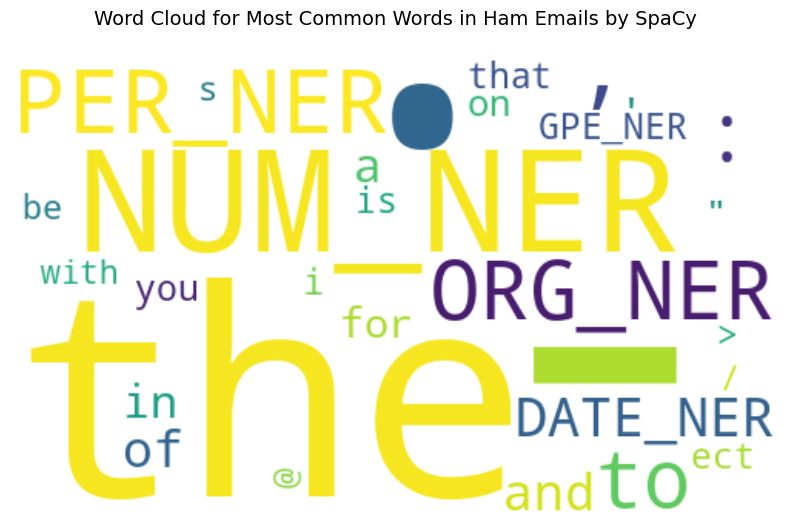

In [ ]:
wordcloud = WordCloud(width=500, height=300, background_color='white').generate_from_frequencies(dict(most_common_words_ham_baseline))
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('Word Cloud for Most Common Words in Ham Emails by SpaCy',pad=25, fontdict={'fontsize':'14'})
plt.axis('off')
# plt.savefig('../images/general/word_cloud_ham_spacy.png', format='png')
plt.savefig('word_cloud_ham_spacy.png', format='png')

In [ ]:
wordcloud = WordCloud(width=500, height=300, background_color='white').generate_from_frequencies(dict(most_common_words_spam_ner))
plt.figure(figsize=(12, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('Word Cloud for Most Common Words in Spam Emails by SpaCy lemmatization',pad=25, fontdict={'fontsize':'14'})
plt.axis('off')
# plt.savefig('../images/general/word_cloud_spam_bert.png', format='png')
plt.savefig('word_cloud_spam_spacy_lemmatization.png', format='png')

In [ ]:
wordcloud = WordCloud(width=500, height=300, background_color='white').generate_from_frequencies(dict(most_common_words_ham_ner))
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('Word Cloud for Most Common Words in Ham Emails by SpaCy lemmatization',pad=25, fontdict={'fontsize':'14'})
plt.axis('off')
plt.savefig('word_cloud_ham_spacy_lemmatization.png', format='png')

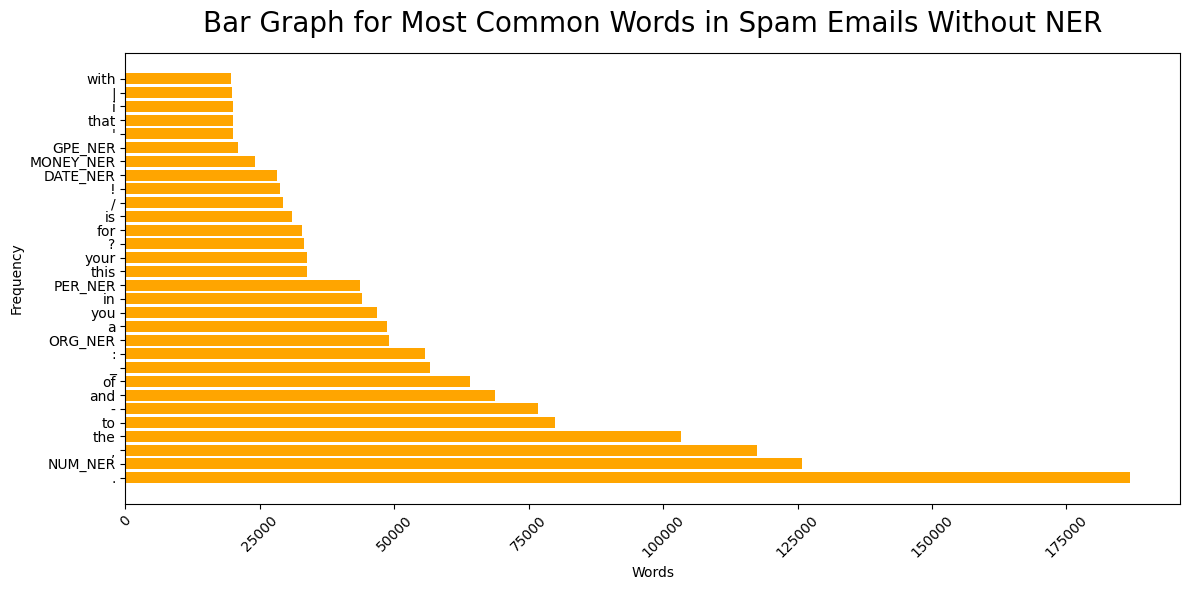

In [ ]:
plt.figure(figsize=(12,6))
words, counts = zip(*most_common_words_spam_baseline)
plt.barh(words, counts, color='orange')
plt.title('Bar Graph for Most Common Words in Spam Emails Without NER',pad=15, fontdict={'fontsize':'20'})
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='center')
plt.tight_layout()
# plt.show()
plt.savefig('common_words_spam_baseline.png', format='png')

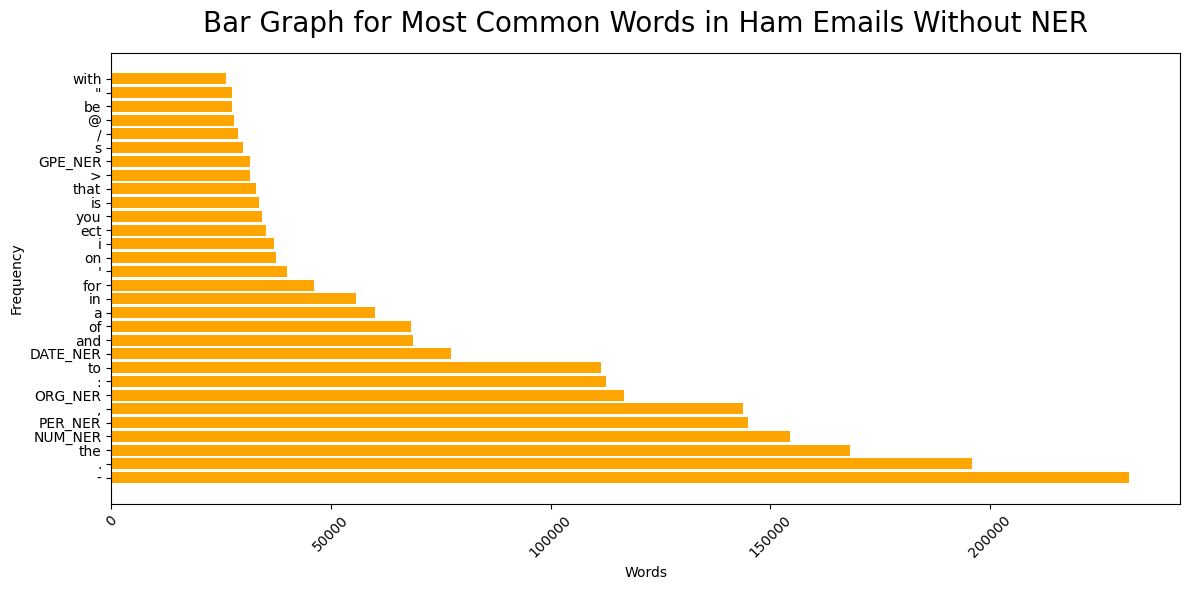

In [ ]:
plt.figure(figsize=(12,6))
words, counts = zip(*most_common_words_ham_baseline)
plt.barh(words, counts, color='orange')
plt.title('Bar Graph for Most Common Words in Ham Emails Without NER',pad=15, fontdict={'fontsize':'20'})
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='center',)
plt.tight_layout()
# plt.show()
plt.savefig('common_words_ham_baseline.png', format='png')

In [ ]:
plt.figure(figsize=(12,6))
words, counts = zip(*most_common_words_spam_ner)
plt.barh(words, counts, color='orange')
plt.title('Bar Graph for Most Common Words in Spam Emails by SpaCy With NER',pad=15, fontdict={'fontsize':'20'})
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='center')
plt.tight_layout()
# plt.show()
plt.savefig('common_words_spam_ner.png', format='png')

In [ ]:
plt.figure(figsize=(12,6))
words, counts = zip(*most_common_words_ham_ner)
plt.barh(words, counts, color='orange')
plt.title('Bar Graph for Most Common Words in Ham Emails by SpaCy With NER',pad=15, fontdict={'fontsize':'20'})
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='center')
plt.tight_layout()
# plt.show()
plt.savefig('common_words_ham_ner.png', format='png')